# Scientific inference

Build a synthetic observation, evaluate its likelihood and fit all 21
parameters of the classic Caustics simulator. This small CPU example
illustrates the workflow. Its short optimizer run does not establish
scientific convergence. The final section shows separate recorded
two-GPU MCMC results from the validated 0.7.0 run.

```{eval-rst}
:download:`Download notebook <inference.ipynb>`
```

## Synthetic data and a proper latent prior

The model contains SIE mass, external shear, Sersic source and lens
light, and PSF convolution. The configured parameter map converts
standard-normal latent coordinates to physical parameters; its median
is defined before generating data and need not equal the truth.

Run this notebook from the project root, or [download the example helpers](../_static/niagara-example-helpers.zip) and extract them beside a downloaded notebook. The helpers are examples, not part of the Niagara wheel.


In [1]:
import importlib.util
import json

import torch

import niagara as ng

missing = [
    name
    for name in ("caustics", "matplotlib", "numpy", "scipy")
    if importlib.util.find_spec(name) is None
]
READY = not missing
if not READY:
    print("SKIPPED: install Niagara's full extra; missing", missing)
else:
    get_ipython().run_line_magic("matplotlib", "inline")
    import matplotlib.pyplot as plt
    import numpy as np
    from scipy.optimize import minimize

    from examples.niagara_examples.caustics import image_problem

    torch.set_num_threads(1)  # This notebook has its own kernel.
    problem = image_problem(32, device="cpu")
    clean = problem.model(problem.truth).detach()
    variance = clean.abs() / 500 + 0.005**2
    generator = torch.Generator(device="cpu").manual_seed(20261026)
    observed = clean + variance.sqrt() * torch.randn(
        clean.shape, generator=generator, dtype=clean.dtype
    )
    z0 = torch.zeros(len(problem.names), dtype=torch.float64)
    print(
        json.dumps(
            {
                "parameters": len(problem.names),
                "pixels": list(clean.shape),
                "device": str(clean.device),
                "seed": 20261026,
                "variance_min": float(variance.min()),
                "variance_max": float(variance.max()),
            },
            indent=2,
        )
    )

{
  "parameters": 21,
  "pixels": [
    32,
    32
  ],
  "device": "cpu",
  "seed": 20261026,
  "variance_min": 4.012418774487673e-05,
  "variance_max": 0.0012483380538291962
}


The likelihood uses fixed known Gaussian variances. The negative log
posterior, up to a constant, is half the weighted residual sum of
squares plus `0.5 * z.square().sum()`. No Jacobian term is required for
this target because the prior is defined in the latent coordinates
being optimized. The data and model are synthetic; no astronomical observations are fitted.

## A short MAP illustration

Niagara is enabled beneath the existing simulator. Each objective call
passes the same packed physical parameters to `problem.model` and uses
ordinary autograd for all 21 latent derivatives. CPU execution keeps
this illustration independent of CUDA availability.


In [2]:
if READY:
    evaluations = []
    with ng.enable(problem.model, default="cpu", backend="torchscript") as engine:

        def objective(values):
            z = torch.tensor(values, dtype=torch.float64, requires_grad=True)
            residual = problem.model(problem.decode(z)) - observed
            loss = 0.5 * (residual.square() / variance).sum() + 0.5 * z.square().sum()
            gradient = torch.autograd.grad(loss, z)[0]
            assert torch.isfinite(loss) and torch.isfinite(gradient).all()
            evaluations.append(float(loss.detach()))
            return float(loss.detach()), gradient.detach().numpy()

        initial_loss, _ = objective(z0.numpy())
        fit = minimize(
            objective,
            z0.numpy(),
            jac=True,
            method="L-BFGS-B",
            options={"maxiter": 40, "maxls": 25, "ftol": 1e-9},
        )
        z_map = torch.tensor(fit.x, dtype=torch.float64)
        with torch.no_grad():
            initial_image = problem.model(problem.decode(z0))
            fitted_image = problem.model(problem.decode(z_map))
            source_x = problem.names.index("source.x0")
            scan_z = torch.linspace(float(z_map[source_x]) - 0.3, float(z_map[source_x]) + 0.3, 25)
            scan_x, scan_loglikelihood = [], []
            for value in scan_z:
                point = z_map.clone()
                point[source_x] = value
                physical = problem.decode(point)
                residual = problem.model(physical) - observed
                scan_x.append(float(physical[source_x]))
                scan_loglikelihood.append(float(-0.5 * (residual.square() / variance).sum()))
            perturbations = z_map + 0.03 * torch.randn(
                (8, len(problem.names)), generator=generator, dtype=torch.float64
            )
            local_images = torch.stack(
                [problem.model(problem.decode(row)) for row in perturbations]
            )
            local_mean = local_images.mean(0)
            local_std = local_images.std(0)
        cache_programs = len(engine.programs)
    print(
        json.dumps(
            {
                "optimizer_success": bool(fit.success),
                "message": str(fit.message),
                "iterations": int(fit.nit),
                "objective_evaluations": len(evaluations),
                "initial_objective": initial_loss,
                "final_objective": float(fit.fun),
                "parameters_fit": len(fit.x),
                "prepared_programs": cache_programs,
            },
            indent=2,
        )
    )

{
  "optimizer_success": false,
  "message": "STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT",
  "iterations": 40,
  "objective_evaluations": 45,
  "initial_objective": 7017.510531940703,
  "final_objective": 511.91540266592176,
  "parameters_fit": 21,
  "prepared_programs": 2
}


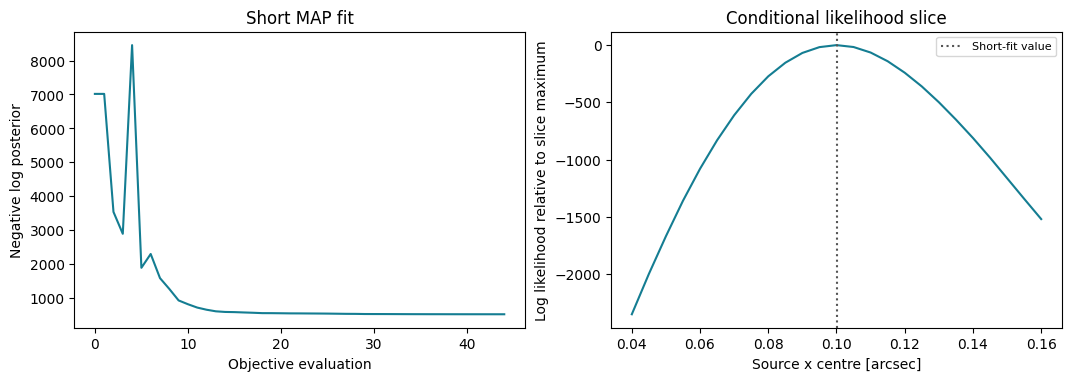

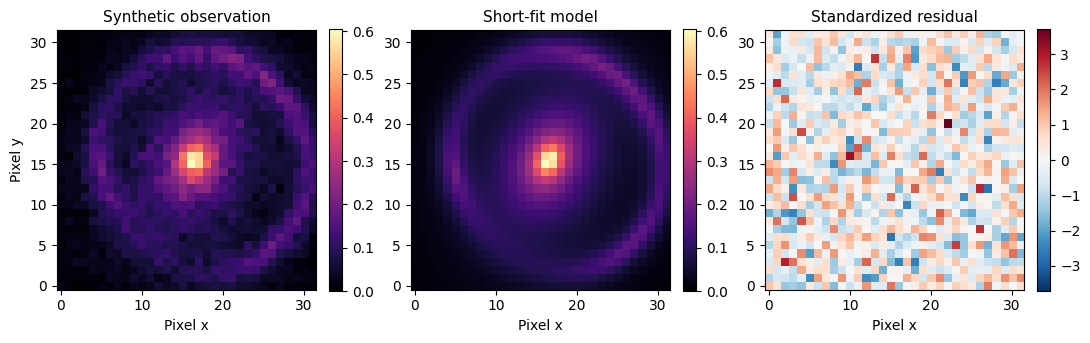

In [3]:
if READY:
    fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.7), constrained_layout=True)
    axes[0].plot(evaluations, color="#147d92", linewidth=1.5)
    axes[0].set_xlabel("Objective evaluation")
    axes[0].set_ylabel("Negative log posterior")
    axes[0].set_title("Short MAP fit")
    scan_values = np.asarray(scan_loglikelihood)
    axes[1].plot(scan_x, scan_values - scan_values.max(), color="#147d92")
    axes[1].axvline(
        float(problem.decode(z_map)[source_x]),
        color="#555555",
        linestyle=":",
        label="Short-fit value",
    )
    axes[1].set_xlabel("Source x centre [arcsec]")
    axes[1].set_ylabel("Log likelihood relative to slice maximum")
    axes[1].set_title("Conditional likelihood slice")
    axes[1].legend(fontsize=8)
    plt.show()

    residual = (observed - fitted_image) / variance.sqrt()
    fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.5), constrained_layout=True)
    vmax = float(torch.stack((observed, fitted_image)).max())
    for ax, image, title in zip(
        axes[:2], (observed, fitted_image), ("Synthetic observation", "Short-fit model")
    ):
        im = ax.imshow(image, origin="lower", cmap="magma", vmin=0, vmax=vmax)
        ax.set_title(title, fontsize=11)
        fig.colorbar(im, ax=ax, shrink=0.8)
    limit = max(3.0, float(residual.abs().max()))
    im = axes[2].imshow(residual, origin="lower", cmap="RdBu_r", vmin=-limit, vmax=limit)
    axes[2].set_title("Standardized residual", fontsize=11)
    fig.colorbar(im, ax=axes[2], shrink=0.8)
    for ax in axes:
        ax.set_xlabel("Pixel x")
    axes[0].set_ylabel("Pixel y")
    plt.show()

Line-search evaluations need not decrease monotonically. Check the
printed optimizer status: reaching the iteration limit still leaves
a short fit. The likelihood slice fixes the other 20 parameters at their
short-fit values. It is a conditional slice, not a marginalized
posterior or uncertainty interval.

## Local image sensitivity

The next plot renders eight small, isotropic latent perturbations with
standard deviation 0.03 around the short fit. These are a local
sensitivity illustration, not posterior samples. The image standard
deviation excludes measurement noise and has no calibrated coverage.


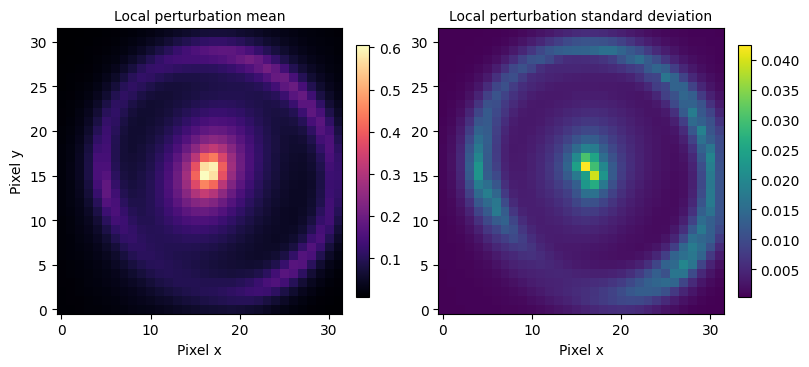

In [4]:
if READY:
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), constrained_layout=True)
    for ax, image, title, cmap in zip(
        axes,
        (local_mean, local_std),
        ("Local perturbation mean", "Local perturbation standard deviation"),
        ("magma", "viridis"),
    ):
        im = ax.imshow(image, origin="lower", cmap=cmap)
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("Pixel x")
        fig.colorbar(im, ax=ax, shrink=0.8)
    axes[0].set_ylabel("Pixel y")
    plt.show()

## Recorded two-GPU posterior validation

The figures below show saved results from the **0.7.0 validated MALA
run**, using the 60-pixel simulator, eight chains and 32,000 retained
draws in total. These cells load the release results; the earlier cells
do not generate them. All 21 parameters met rank-normalized split
R-hat below 1.01 and bulk and tail ESS of at least 400. The recorded
two-GPU maximum R-hat was 1.003096, with minimum bulk ESS 2055 and tail
ESS 1991. These diagnostics describe the sampled chains. They leave open the
possibility of missed posterior modes.

The interval figure uses physical parameter coordinates. Its posterior
predictive parameter variation excludes new measurement noise. The
[validation page](../development/validation.md) records the exact
software and hardware used for validation.


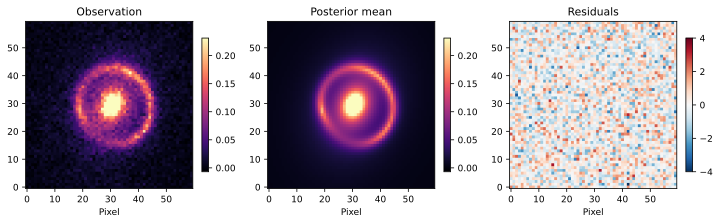

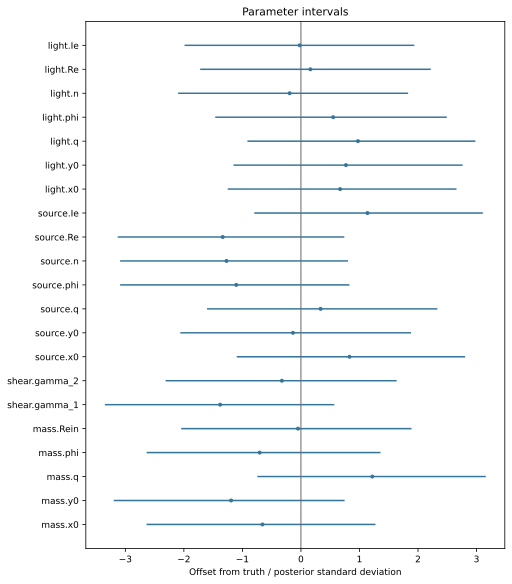

Recorded physical-parameter summary: G:\Qsync\Maitrise\Projects\Niagara\docs\source\_static\results\0.7.0\mcmc_two_gpu\mala_summary.csv


In [5]:
from pathlib import Path

evidence = next(
    (
        path / "docs/source/_static/results/0.7.0/mcmc_two_gpu"
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "docs/source/_static/results/0.7.0/mcmc_two_gpu").is_dir()
    ),
    None,
)
if evidence is None:
    print("Recorded MCMC figures are available in the documentation release assets.")
else:
    from IPython.display import SVG, display

    for filename in ("images.svg", "intervals.svg"):
        display(SVG(data=(evidence / filename).read_text(encoding="utf-8")))
    print("Recorded physical-parameter summary:", evidence / "mala_summary.csv")

## Run the maintained inference program

```console
python examples/caustics_mcmc.py --device cuda:0 --source-device cuda:1 --size 60 --chains 8 --warmup 1500 --samples 4000 --plot --out results/my_mcmc
```

Use a fresh output directory and run a small smoke configuration before
a costly job. The program checks every latent gradient
against ordinary autograd and finite differences, fits MAP, constructs
fixed Gauss-Newton whitening and prepares batched MALA transitions.
Whitening is a fixed proposal coordinate transform. MALA retains its
Metropolis correction; warmup adapts a shared step size, while
production sampling keeps that step size fixed. Production does not
accumulate a growing autograd tape.

Vectorized emcee is also supported. Its interacting walkers are not
independent chains for a naive between-chain R-hat calculation. Reliable
autocorrelation-time checks need an appropriately long run.

Record compilation, MAP, whitening, transition preparation, warmup and
production separately. Faster rendering does not guarantee a faster
complete inference job; transfers can dominate a small two-GPU scene.
Preserve data, variances, priors, draws, diagnostics and predictive
figures. Assess numerical checks and chain diagnostics alongside the images; a
short smoke run alone cannot establish convergence.
